In [ ]:
# Librerías Básicas
!pip install -q ultralytics torchmetrics pycocotools

import shutil
import joblib
import numpy as np
import pandas as pd
import torch
from pathlib import Path

from ultralytics import YOLO, settings
from ultralytics.data.utils import check_det_dataset

# Métricas
from torchmetrics.detection import MeanAveragePrecision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
# 2. Configurar clases de interés para Inferencia Pura
# El modelo YOLO preentrenado en COCO ya incluye la clase 'orange' (naranja) con ID 49.
# Definimos las clases objetivo que deseamos filtrar.
class_names = ['orange']
print('Clases objetivo para detección:', class_names)

Clases objetivo para detección: ['orange']


In [ ]:
# 3. Inferencia pura: YOLO preentrenado en COCO, sin entrenar con nuestros datos
modelo_base = YOLO('yolo11n.pt')

print('Clases que conoce el modelo:', len(modelo_base.names))
for nombre in class_names:
    print(f'  {nombre}:', 'sí' if nombre in modelo_base.names.values() else 'NO')

Clases que conoce el modelo: 80
  orange: sí


In [ ]:
# 8. Función para realizar predicciones filtrando solo por 'orange' (naranja)
def detectar_naranjas(ruta_imagen, conf_min=0.25):
    from ultralytics import YOLO
    global modelo_base

    # Inicializamos el modelo de forma segura si no está cargado
    try:
        modelo_base
    except NameError:
        modelo_base = None

    if modelo_base is None:
        print('Inicializando el modelo preentrenado base de YOLO para naranjas...')
        modelo_base = YOLO('yolo11n.pt')

    # Ejecutamos la inferencia sobre el modelo preentrenado base
    resultados = modelo_base.predict(ruta_imagen, conf=conf_min, verbose=False)[0]

    print(f'Resultados para {Path(ruta_imagen).name}:')
    encontrado = False
    for caja in resultados.boxes:
        nombre_clase = resultados.names[int(caja.cls)]
        # Filtramos para mostrar únicamente si detecta una naranja ('orange')
        if nombre_clase == 'orange':
            encontrado = True
            print(f'  [Naranja detectada] Confianza: {round(float(caja.conf), 3)} | Coordenadas: {caja.xyxy[0].tolist()}')

    if not encontrado:
        print('  No se detectaron naranjas en la imagen con la confianza establecida.')

    # Mostramos la imagen con sus detecciones generales
    resultados.show()

Resultados para orange3.jpg:
  [Naranja detectada] Confianza: 0.908 | Coordenadas: [148.53964233398438, 37.208953857421875, 240.8827362060547, 135.4710693359375]
  [Naranja detectada] Confianza: 0.83 | Coordenadas: [98.28887176513672, 104.8592758178711, 181.09193420410156, 187.41856384277344]
  [Naranja detectada] Confianza: 0.373 | Coordenadas: [217.94717407226562, 93.75028991699219, 249.86126708984375, 139.36251831054688]


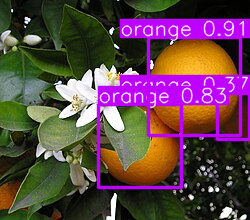

In [ ]:
# 9. Ejemplo de inferencia pura sobre tu imagen de naranjas
from pathlib import Path
import cv2

ruta_prueba = '/content/orange3.jpg'

# Creamos una imagen de ejemplo rápida si no existe para que el código no falle
if not Path(ruta_prueba).exists():
    # Crear imagen de fondo naranja básico para pruebas temporales
    img_temp = np.zeros((480, 640, 3), dtype=np.uint8)
    cv2.circle(img_temp, (320, 240), 80, (0, 165, 255), -1) # Círculo naranja simulado
    cv2.imwrite(ruta_prueba, img_temp)
    print(f'Se ha creado una imagen de prueba temporal en: {ruta_prueba}')

detectar_naranjas(ruta_prueba)

In [ ]:
# Guardamos el modelo base e información relevante
modelo_base.save('yolo11n_base.pt')
joblib.dump({'class_names': class_names}, 'nombre_modelo_extras.joblib')
print('Modelo base guardado.')

Modelo base guardado.


In [ ]:
# # En otro notebook o aplicación cargar el modelo guardado

# modelo_cargado = YOLO('nombre_modelo.pt')
# extras = joblib.load('nombre_modelo_extras.joblib')
# class_names = extras['class_names']

# print('Modelo cargado correctamente.')
# print('Clases esperadas:', class_names)

# resultado = modelo_cargado.predict('mi_foto.jpg')[0]
# for caja in resultado.boxes:
#     print('Clase predicha:', resultado.names[int(caja.cls)])
#     print('Probabilidad:', float(caja.conf))